# Solar vs Coal: Forecasting India's Energy Transition with Time Series Models

**Mini Project: Applied Time Series Analysis**

**Topic:** Modelling and forecasting monthly electricity generation by source (coal, solar, total demand) for India, estimating *when solar will overtake coal* as a probability distribution, and testing whether India is on track for its **500 GW non-fossil capacity target by 2030**. The same pipeline is then run automatically on 80+ countries and deployed as an interactive web app.

**Dataset:** [Ember](https://ember-energy.org) monthly and yearly electricity data (free, CC-BY-4.0), compiled from national grid operators and statistics agencies. Files used: `data/ember_monthly_global.csv` and `data/ember_yearly_global.csv`, submitted with this notebook.

**Deliverables:** this notebook · `transition.py` (shared modelling library) · `build_results.py` (multi-country batch pipeline) · `app.py` (Streamlit app with live model fitting) · a published interactive dashboard.

---
## Contents
1. Introduction and research questions
2. Data collection
3. Dealing with missing values
4. Exploratory data analysis
5. Stationarity: ADF and KPSS tests
6. Transformations
7. Seasonality and STL decomposition
8. ACF and PACF
9. Identifying the model (AR / MA / ARMA / ARIMA / SARIMA)
10. Identifying lags with AIC and BIC
11. Model evaluation: hold-out, cross-validation and residual diagnostics
12. 24-month forecasts
13. Extension A: when will solar overtake coal? (probabilistic first-passage analysis)
14. Extension B: will India reach 500 GW of non-fossil capacity by 2030?
15. Extension C: the same pipeline on 80+ countries, and how well calibrated it is
16. Deployment
17. Conclusion, limitations and references

## 1. Introduction and research questions
India is the world's third-largest electricity producer and still generates about three quarters of its power from coal, while solar generation has grown roughly six-fold since 2019. Whether, and when, solar overtakes coal is one of the most consequential questions for global emissions.

Most time series projects stop at "fit SARIMA, plot forecast". Here the forecasts are used to answer decision-relevant questions, and every claim is backed by an out-of-sample test.

| # | Research question | Method |
|---|---|---|
| RQ1 | How accurately can monthly coal, solar and total generation be forecast 1-12 months ahead? | SARIMA vs Holt-Winters vs seasonal naive; hold-out and rolling-origin cross-validation |
| RQ2 | When will solar overtake coal in India, and with what probability? | SARIMA on the log-ratio log(solar/coal); 2,000 simulated future paths; first-passage-time distribution |
| RQ3 | Will India hit 500 GW of non-fossil capacity by 2030 on current trends? | ARIMA on log annual capacity under two growth assumptions; backtested |
| RQ4 | Does the method generalise, and are its uncertainty intervals honest? | Automated pipeline over 80+ countries; coverage of 80% prediction intervals |

**Novel elements:** (a) the crossover date is estimated as a *probability distribution* via simulation, not a single extrapolated line; (b) model selection uses AIC/BIC *within* each valid differencing scheme and time-series cross-validation *across* schemes; (c) the probabilistic forecasts are checked for calibration across many countries; (d) the full analysis is deployed as an interactive app.

## 2. Data collection

In [1]:
import os, sys, warnings, json
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display

import transition as T   # project library: every model in the app and dashboard uses the same code

# Chart style: validated colour-blind-safe categorical palette, thin marks, recessive grid
C = {"coal": "#2a78d6", "solar": "#eb6834", "total": "#1baf7a", "wind": "#e87ba4", "hydro": "#6250d6",
     "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "lines.linewidth": 1.8, "legend.frameon": False, "font.size": 9.5,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})
pd.set_option("display.precision", 3)

In [2]:
MONTHLY, YEARLY = "data/ember_monthly_global.csv", "data/ember_yearly_global.csv"
os.makedirs("data", exist_ok=True)
for path, url in [(MONTHLY, T.MONTHLY_URL), (YEARLY, T.YEARLY_URL)]:
    if not os.path.exists(path):              # download once, then reuse the saved copy
        pd.read_csv(url).to_csv(path, index=False)
        print("downloaded", url)

raw = pd.read_csv(MONTHLY, low_memory=False, parse_dates=["Date"])
print("Raw monthly file:", raw.shape, "| columns:", list(raw.columns[:8]), "...")
monthly = T.load_monthly(MONTHLY)
yearly = T.load_yearly(YEARLY)
print("Countries:", monthly["Area"].nunique(), "| sources:", sorted(monthly["Electricity source"].unique()))
print("Date range:", monthly["Date"].min().date(), "to", monthly["Date"].max().date())

Raw monthly file: (181459, 23) | columns: ['Area', 'ISO 3 code', 'Date', 'Area type', 'Electricity source', 'Is aggregated source', 'Generation (TWh)', 'Generation YoY change (TWh)'] ...


Countries: 88 | sources: ['Bioenergy', 'Clean', 'Coal', 'Demand', 'Fossil', 'Gas', 'Hydro', 'Hydro, bioenergy and other renewables', 'Net imports', 'Nuclear', 'Other fossil', 'Other renewables', 'Renewables', 'Solar', 'Total generation', 'Wind', 'Wind and solar']
Date range: 1998-12-01 to 2026-09-01


In [3]:
india = T.country_panel(monthly, "India")          # rows = months, columns = sources (TWh)
COUNTRY = "India"
y_coal, y_solar, y_total = india["Coal"], india["Solar"], india["Total generation"]
print(f"India: {india.index[0]:%b %Y} to {india.index[-1]:%b %Y} ({len(india)} months)")
india[["Coal", "Gas", "Hydro", "Nuclear", "Wind", "Solar", "Total generation"]].tail()

India: Jan 2019 to Aug 2026 (92 months)


Electricity source,Coal,Gas,Hydro,Nuclear,Wind,Solar,Total generation
Date,,,,,,,
2026-04-01,118.770,2.165,11.353,5.148,6.849,24.903,170.271
2026-05-01,121.884,2.181,13.373,5.714,11.458,25.837,181.392
2026-06-01,120.202,2.254,13.999,5.564,15.256,24.675,182.779
2026-07-01,117.181,2.137,18.900,5.400,18.505,21.855,184.784
2026-08-01,114.849,1.981,22.249,5.052,17.792,21.213,183.859


## 3. Dealing with missing values
Three kinds of data problems can occur in this dataset: (1) months missing for a country, (2) zero or negative values that break a log transform (e.g. solar before it existed), (3) countries whose reporting starts late or stops early.

**Policy used everywhere in the project** (`clean_series` in `transition.py`): interpolate gaps of at most two months on the log scale, then keep the most recent contiguous run of positive values, so every forecast starts from the latest month. Longer gaps are not invented.

In [4]:
full = monthly.pivot_table(index=["Area", "Date"], columns="Electricity source", values="Generation (TWh)")
by_country = full.groupby(level=0).apply(lambda g: pd.Series({
    "first": g.index.get_level_values(1).min().strftime("%Y-%m"),
    "last": g.index.get_level_values(1).max().strftime("%Y-%m"),
    "months": len(g),
    "expected": len(pd.date_range(g.index.get_level_values(1).min(), g.index.get_level_values(1).max(), freq="MS")),
    "missing cells (coal/solar)": int(g[["Coal", "Solar"]].isna().sum().sum()),
    "zero solar months": int((g["Solar"] == 0).sum()) if "Solar" in g else len(g)}))
by_country["gap months"] = by_country["expected"] - by_country["months"]
print("Countries with gaps in their monthly record:", int((by_country["gap months"] > 0).sum()))
print("Countries with any zero-solar month:", int((by_country["zero solar months"] > 0).sum()))
display(by_country.loc[["India"]])
print("India missing values per column:", int(india.isna().sum().sum()))

Countries with gaps in their monthly record: 0
Countries with any zero-solar month: 29


,first,last,months,expected,missing cells (coal/solar),zero solar months,gap months
Area,,,,,,,
India,2019-01,2026-08,92,92,0,0,0


India missing values per column: 0


In [5]:
# Demonstrate the cleaning rule on the country with the most problems
sys.path.insert(0, ".")
from transition import clean_series
worst = by_country.sort_values(["gap months", "zero solar months"], ascending=False).index[0]
s = T.country_panel(monthly, worst)["Solar"]
cleaned = clean_series(s)
print(f"{worst}: {len(s)} months, {int(s.isna().sum())} missing, {int((s <= 0).sum())} non-positive "
      f"-> kept {len(cleaned)} contiguous months ({cleaned.index[0]:%Y-%m} to {cleaned.index[-1]:%Y-%m})")

Ireland: 201 months, 0 missing, 159 non-positive -> kept 42 contiguous months (2023-04 to 2026-09)


India's record is complete (no missing months and no zero values), so no imputation is needed for the main analysis. The rule above matters for the multi-country pipeline in Section 15.

## 4. Exploratory data analysis
### 4.1 Line graphs

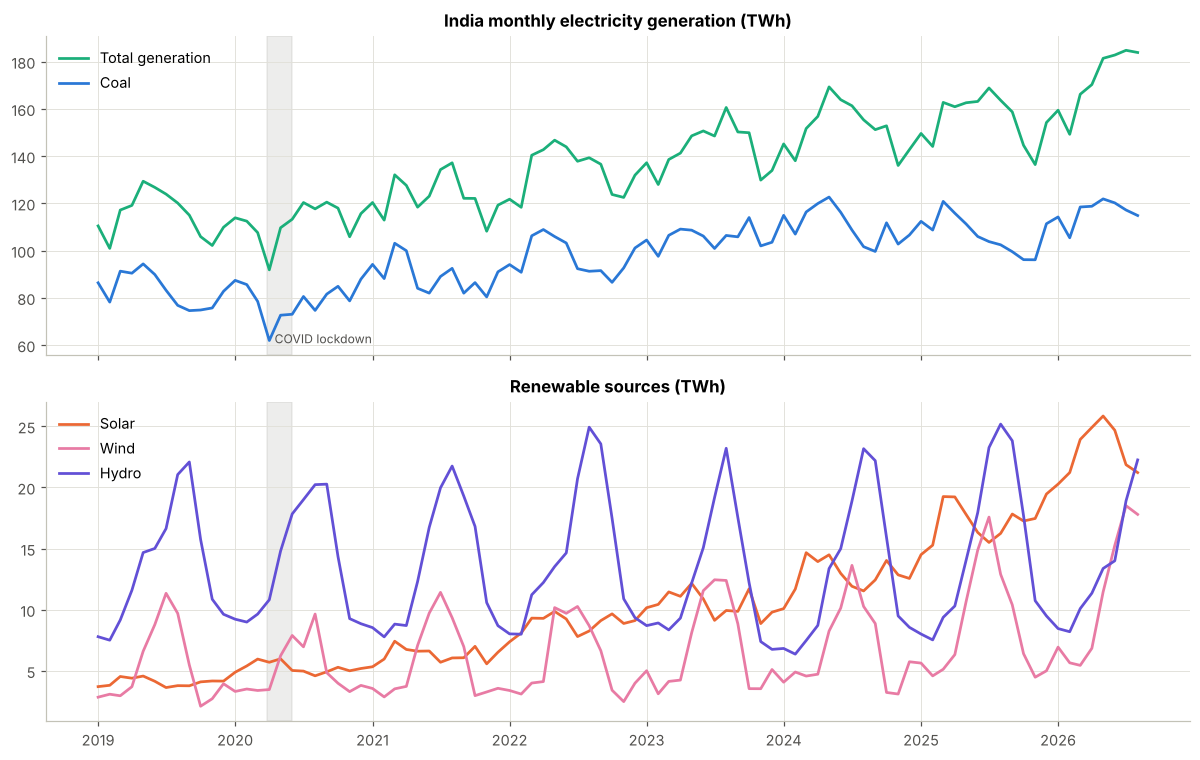

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(y_total, color=C["total"], label="Total generation")
ax[0].plot(y_coal, color=C["coal"], label="Coal")
ax[0].set_title("India monthly electricity generation (TWh)"); ax[0].legend(loc="upper left")
for s, c in [("Solar", "solar"), ("Wind", "wind"), ("Hydro", "hydro")]:
    ax[1].plot(india[s], color=C[c], label=s)
ax[1].set_title("Renewable sources (TWh)"); ax[1].legend(loc="upper left")
ax[1].axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color=C["muted"], alpha=0.15)
ax[0].axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color=C["muted"], alpha=0.15)
ax[0].text(pd.Timestamp("2020-04-15"), ax[0].get_ylim()[0] + 5, "COVID lockdown", color=C["ink2"], fontsize=8)
plt.tight_layout(); plt.show()

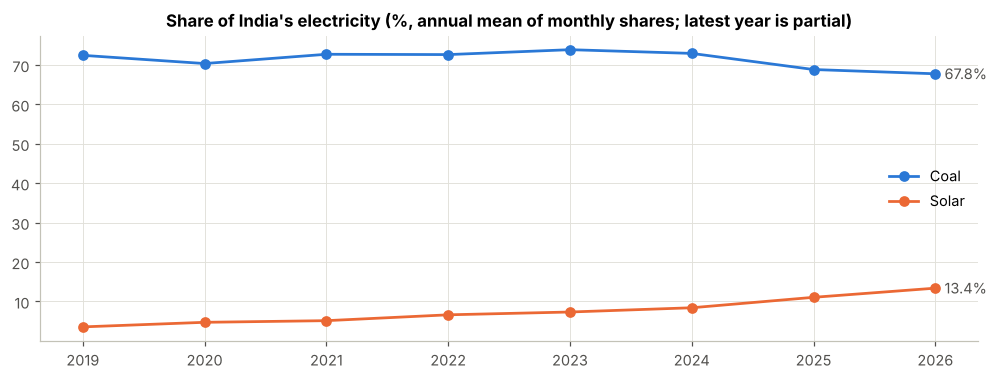

In [7]:
share = india[["Coal", "Solar", "Wind", "Hydro"]].div(india["Total generation"], axis=0).mul(100)
annual_share = share.resample("YS").mean(); annual_share.index = annual_share.index.year
fig, ax = plt.subplots(figsize=(11, 3.6))
for s, c in [("Coal", "coal"), ("Solar", "solar")]:
    ax.plot(annual_share.index, annual_share[s], marker="o", color=C[c], label=s)
    ax.annotate(f"{annual_share[s].iloc[-1]:.1f}%", (annual_share.index[-1], annual_share[s].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=C["ink2"])
ax.set_title("Share of India's electricity (%, annual mean of monthly shares; latest year is partial)"); ax.legend()
plt.show()

### 4.2 Scatter plots

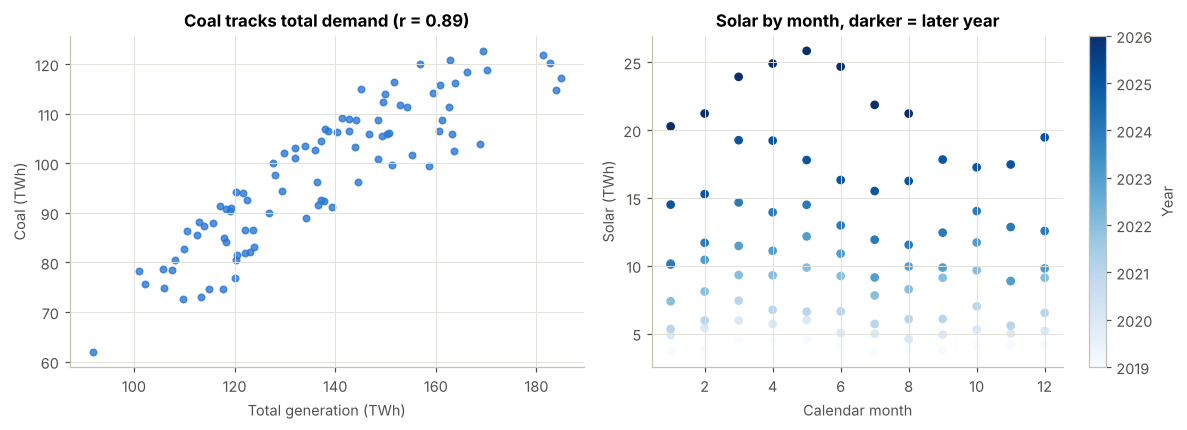

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_total, y_coal, s=18, color=C["coal"], alpha=0.8)
r1 = np.corrcoef(y_total, y_coal)[0, 1]
ax[0].set_xlabel("Total generation (TWh)"); ax[0].set_ylabel("Coal (TWh)"); ax[0].set_title(f"Coal tracks total demand (r = {r1:.2f})")
sc = ax[1].scatter(india.index.month, y_solar, c=india.index.year, cmap="Blues", s=22)
ax[1].set_xlabel("Calendar month"); ax[1].set_ylabel("Solar (TWh)"); ax[1].set_title("Solar by month, darker = later year")
plt.colorbar(sc, ax=ax[1], label="Year"); plt.tight_layout(); plt.show()

Coal moves almost one-for-one with total demand: it is the balancing source. Solar shows both a strong upward trend (each year sits above the last) and a seasonal shape (spring peak, monsoon dip in July-August).

### 4.3 Histograms and QQ plots

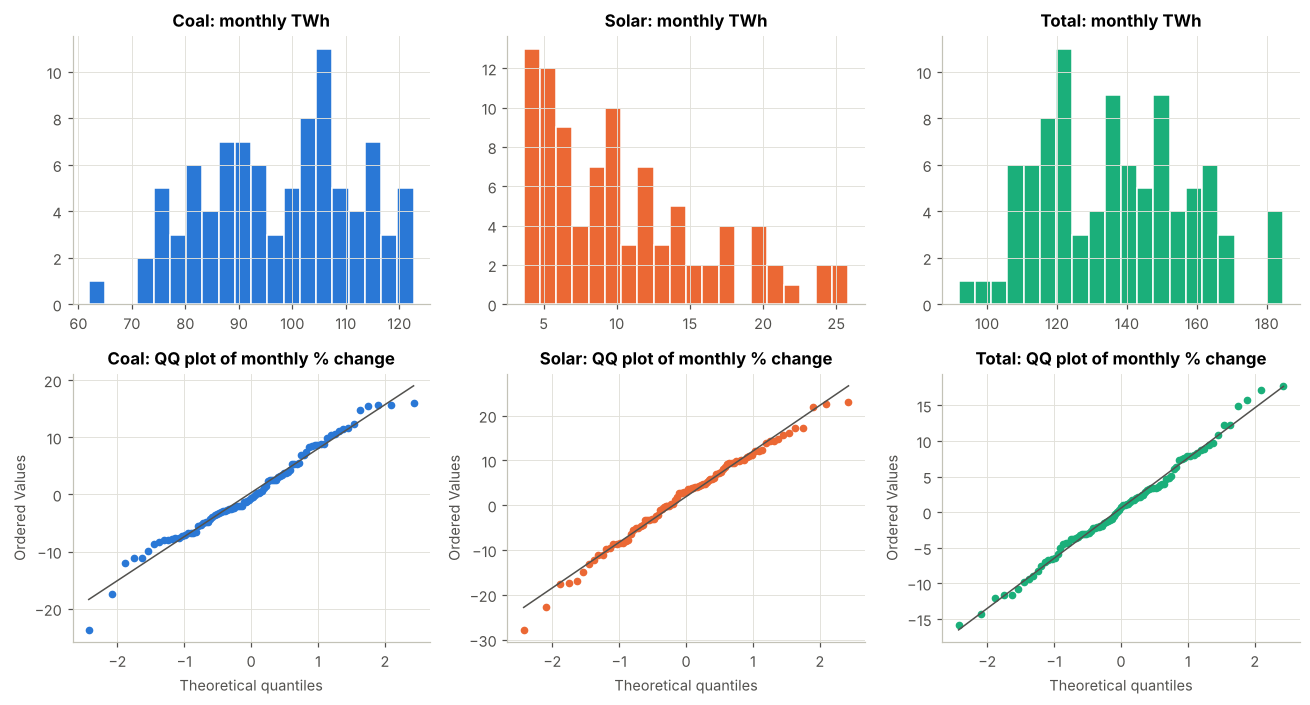

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6.5))
series = {"Coal": y_coal, "Solar": y_solar, "Total": y_total}
for i, (name, s) in enumerate(series.items()):
    g = np.log(s).diff().dropna() * 100             # month-on-month growth, %
    ax[0, i].hist(s, bins=20, color=list(C.values())[i], edgecolor="white")
    ax[0, i].set_title(f"{name}: monthly TWh")
    stats.probplot(g, dist="norm", plot=ax[1, i])
    ax[1, i].get_lines()[0].set(markersize=4, color=list(C.values())[i]); ax[1, i].get_lines()[1].set(color=C["ink2"], lw=1)
    ax[1, i].set_title(f"{name}: QQ plot of monthly % change")
plt.tight_layout(); plt.show()

The level histograms are skewed or bimodal because of trend, which is a first hint of non-stationarity. The QQ plots of month-on-month changes are close to the normal line in the centre with heavier tails, mostly the COVID months, which motivates the intervention variable used later.

### 4.4 Descriptive statistics

In [10]:
def describe(s):
    s = s.dropna(); yrs = (s.index[-1] - s.index[0]).days / 365.25
    first12, last12 = s.iloc[:12].sum(), s.iloc[-12:].sum()
    return pd.Series({"mean": s.mean(), "std": s.std(), "min": s.min(), "max": s.max(),
                      "CV (%)": s.std() / s.mean() * 100, "skewness": stats.skew(s), "kurtosis": stats.kurtosis(s),
                      "growth, first vs last 12m (%/yr)": ((last12 / first12) ** (1 / (yrs - 1)) - 1) * 100})
desc = pd.DataFrame({s: describe(india[s]) for s in ["Coal", "Gas", "Hydro", "Wind", "Solar", "Nuclear", "Total generation"]}).T
desc.round(2)

,mean,std,min,max,CV (%),skewness,kurtosis,"growth, first vs last 12m (%/yr)"
Coal,97.74,14.13,61.94,122.67,14.46,-0.19,-0.85,4.50
Gas,2.93,1.04,1.43,5.23,35.36,0.44,-0.93,-10.36
Hydro,13.57,5.33,6.37,25.18,39.27,0.58,-0.94,0.61
Wind,6.71,3.84,2.11,18.50,57.27,1.14,0.69,9.38
Solar,10.46,5.76,3.64,25.84,55.08,0.90,-0.04,28.60
Nuclear,4.11,0.63,2.70,5.71,15.41,0.32,-0.27,4.10
Total generation,136.95,21.21,91.85,184.78,15.49,0.25,-0.67,5.56


## 5. Stationarity: ADF and KPSS tests
- **ADF** (Augmented Dickey-Fuller): H0 = unit root (non-stationary). Reject when p < 0.05.
- **KPSS**: H0 = stationary. Reject when p < 0.05.

Using both protects against the low power of ADF on short series: we call a series stationary only when ADF rejects *and* KPSS does not.

In [11]:
ratio = T.log_ratio(y_solar, y_coal)       # used in Section 13
tests = pd.DataFrame([T.stationarity_report(s, n) for n, s in
                      [("Coal", y_coal), ("Solar", y_solar), ("Total", y_total), ("log(Solar/Coal)", ratio)]])
tests

,Series,ADF stat,ADF p-value,KPSS p-value,Verdict
0,Coal,-0.554,0.881,0.01,non-stationary
1,Solar,3.725,1.000,0.01,non-stationary
2,Total,0.850,0.992,0.01,non-stationary
3,log(Solar/Coal),0.080,0.965,0.01,non-stationary


All four series in levels are non-stationary: they have trends, and solar's trend is exponential. They need transforming before ARMA-type models can be used.

## 6. Transformations
### 6.1 Variance-stabilising transform (Box-Cox)
Box-Cox finds the power λ that best stabilises the variance (λ = 0 means log, λ = 1 means no transform).

{'Coal': np.float64(1.49), 'Solar': np.float64(-0.1), 'Total': np.float64(0.13)}


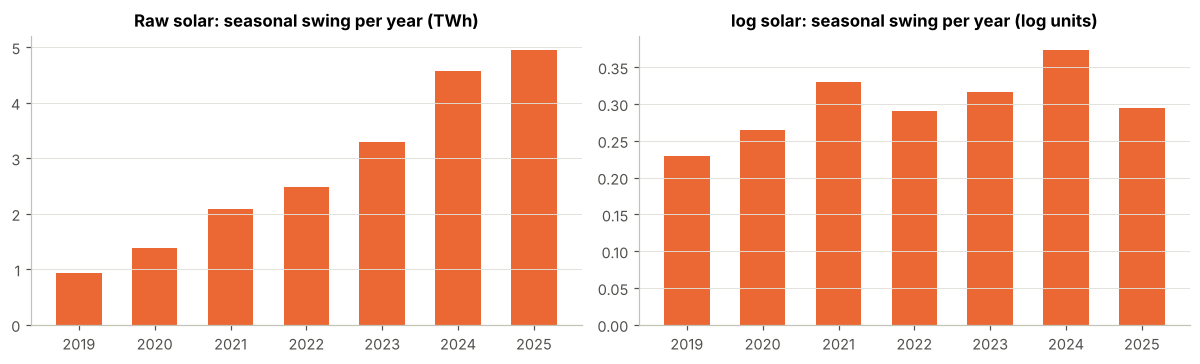

Date,2019,2020,2021,2022,2023,2024,2025
raw (TWh),0.94,1.39,2.09,2.48,3.29,4.57,4.96
log,0.23,0.26,0.33,0.29,0.32,0.37,0.29


In [12]:
lam = {n: stats.boxcox(s)[1] for n, s in series.items()}
print({k: round(v, 2) for k, v in lam.items()})
# Size of the seasonal swing each year: max minus min month, on the raw and the log scale
full_years = y_solar[y_solar.index.year < y_solar.index[-1].year]
swing = pd.DataFrame({"raw (TWh)": full_years.groupby(full_years.index.year).agg(lambda v: v.max() - v.min()),
                      "log": np.log(full_years).groupby(full_years.index.year).agg(lambda v: v.max() - v.min())})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(swing.index, swing["raw (TWh)"], color=C["solar"], width=0.6); ax[0].set_title("Raw solar: seasonal swing per year (TWh)")
ax[1].bar(swing.index, swing["log"], color=C["solar"], width=0.6); ax[1].set_title("log solar: seasonal swing per year (log units)")
for a in ax: a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
swing.round(2).T

Solar's λ ≈ 0, so a **log transform** is right: solar grows by a roughly constant *percentage*, and its seasonal swing grows with its level (multiplicative seasonality), which a log turns into an additive one. Coal's λ is above 1, but the gain from transforming coal is small. We use logs for all generation series so that (a) forecasts can never be negative, (b) model errors are percentages, and (c) the log-ratio in Section 13 is just log(solar) − log(coal).

### 6.2 Differencing
We test every candidate differencing scheme on the log series: first difference (d = 1), seasonal difference (D = 1, lag 12), or both.

In [13]:
rows = []
for n, s in [("log Coal", np.log(y_coal)), ("log Solar", np.log(y_solar)), ("log Total", np.log(y_total)), ("log(Solar/Coal)", ratio)]:
    for d, D in [(0, 0), (1, 0), (0, 1), (1, 1)]:
        z = s.diff(12) if D else s
        z = z.diff() if d else z
        rows.append({**T.stationarity_report(z, n), "d": d, "D": D})
diff_tests = pd.DataFrame(rows).set_index(["Series", "d", "D"])[["ADF p-value", "KPSS p-value", "Verdict"]]
diff_tests

ADF p-value  KPSS p-value         Verdict
Series          d D                                           
log Coal        0 0    1.372e-01          0.01  non-stationary
                1 0    0.000e+00          0.10      stationary
                0 1    3.352e-01          0.10  non-stationary
                1 1    5.000e-04          0.10      stationary
log Solar       0 0    9.897e-01          0.01  non-stationary
                1 0    6.100e-02          0.10  non-stationary
                0 1    4.000e-04          0.10      stationary
                1 1    1.251e-01          0.10  non-stationary
log Total       0 0    9.801e-01          0.01  non-stationary
                1 0    0.000e+00          0.10      stationary
                0 1    1.146e-01          0.10  non-stationary
                1 1    2.000e-04          0.10      stationary
log(Solar/Coal) 0 0    9.647e-01          0.01  non-stationary
                1 0    1.208e-01          0.10  non-stationary
                0 1    3.899e-01          0.10  non-stationary
                1 1    2.000e-04          0.10      stationary

In [14]:
for n, s in [("log Coal", np.log(y_coal)), ("log Solar", np.log(y_solar)), ("log Total", np.log(y_total)), ("log(Solar/Coal)", ratio)]:
    print(f"{n:17s} accepted (d, D) schemes: {T.differencing_candidates(s)}")

log Coal          accepted (d, D) schemes: [(1, 0), (1, 1)]
log Solar         accepted (d, D) schemes: [(0, 1)]
log Total         accepted (d, D) schemes: [(1, 0), (1, 1)]
log(Solar/Coal)   accepted (d, D) schemes: [(1, 1)]


For solar, only seasonal differencing gives a stationary series. For coal and total demand, *more than one* scheme passes both tests, so the tests alone cannot choose. We resolve this in Section 10 with out-of-sample accuracy, because AIC cannot compare models with different differencing (they are fitted to different numbers of observations).

## 7. Seasonality and STL decomposition

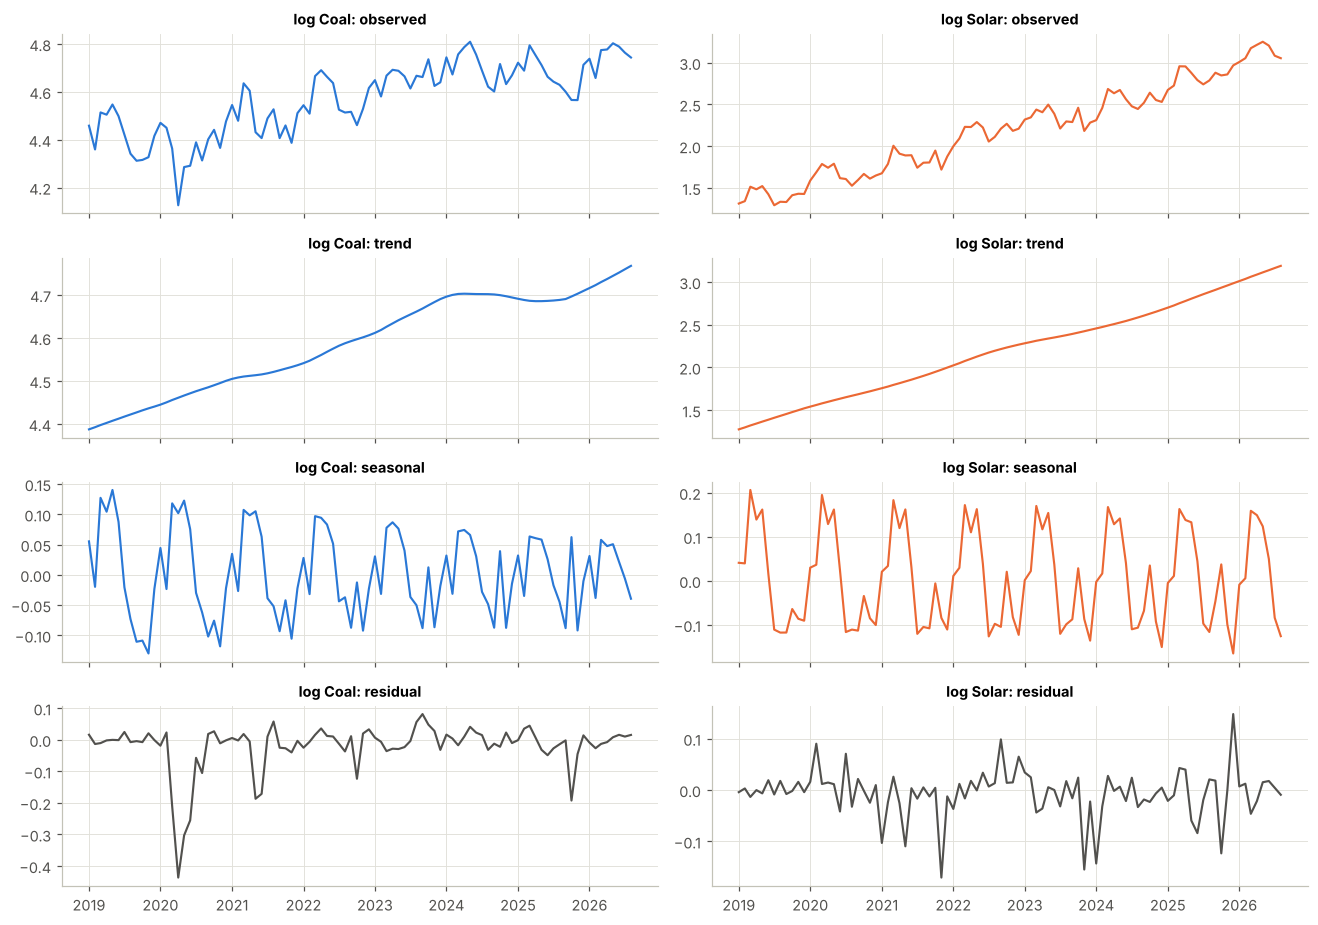

,Seasonal strength F_s,Trend strength F_t
log Coal,0.17,0.73
log Solar,0.82,0.99


In [15]:
fig, axes = plt.subplots(4, 2, figsize=(12, 8.5), sharex=True)
fs = {}
for j, (name, s, c) in enumerate([("log Coal", np.log(y_coal), "coal"), ("log Solar", np.log(y_solar), "solar")]):
    res = STL(s, period=12, robust=True).fit()
    for i, (part, v) in enumerate([("observed", res.observed), ("trend", res.trend), ("seasonal", res.seasonal), ("residual", res.resid)]):
        axes[i, j].plot(v, color=C[c] if part != "residual" else C["ink2"], lw=1.4)
        axes[i, j].set_title(f"{name}: {part}", fontsize=9.5)
    fs[name] = (T.seasonal_strength(s), max(0, 1 - res.resid.var() / (res.trend + res.resid).var()))
plt.tight_layout(); plt.show()
pd.DataFrame(fs, index=["Seasonal strength F_s", "Trend strength F_t"]).T.round(2)

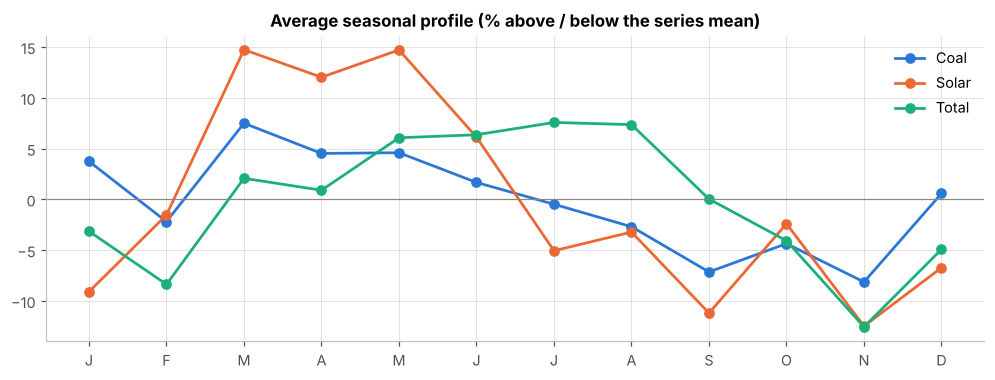

In [16]:
prof = pd.DataFrame({n: np.log(s).groupby(s.index.month).mean() - np.log(s).mean() for n, s in series.items()}) * 100
fig, ax = plt.subplots(figsize=(11, 3.6))
for n, c in [("Coal", "coal"), ("Solar", "solar"), ("Total", "total")]:
    ax.plot(range(1, 13), prof[n], marker="o", color=C[c], label=n)
ax.axhline(0, color=C["muted"], lw=0.8); ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_title("Average seasonal profile (% above / below the series mean)"); ax.legend(); plt.show()

- **Solar** has strong seasonality (F_s > 0.8): it peaks in March-May (clear skies, long days) and dips in July-August (monsoon clouds).
- **Coal** has weaker seasonality. It is high in the pre-monsoon summer (air-conditioning demand) and low in the monsoon, when demand is lower and hydro and wind are high. The robust STL places the 2020 lockdown in the residual.
- Both series are dominated by trend (F_t ≈ 1).

## 8. ACF and PACF
Plotted for the stationary (differenced) log series chosen by the tests.

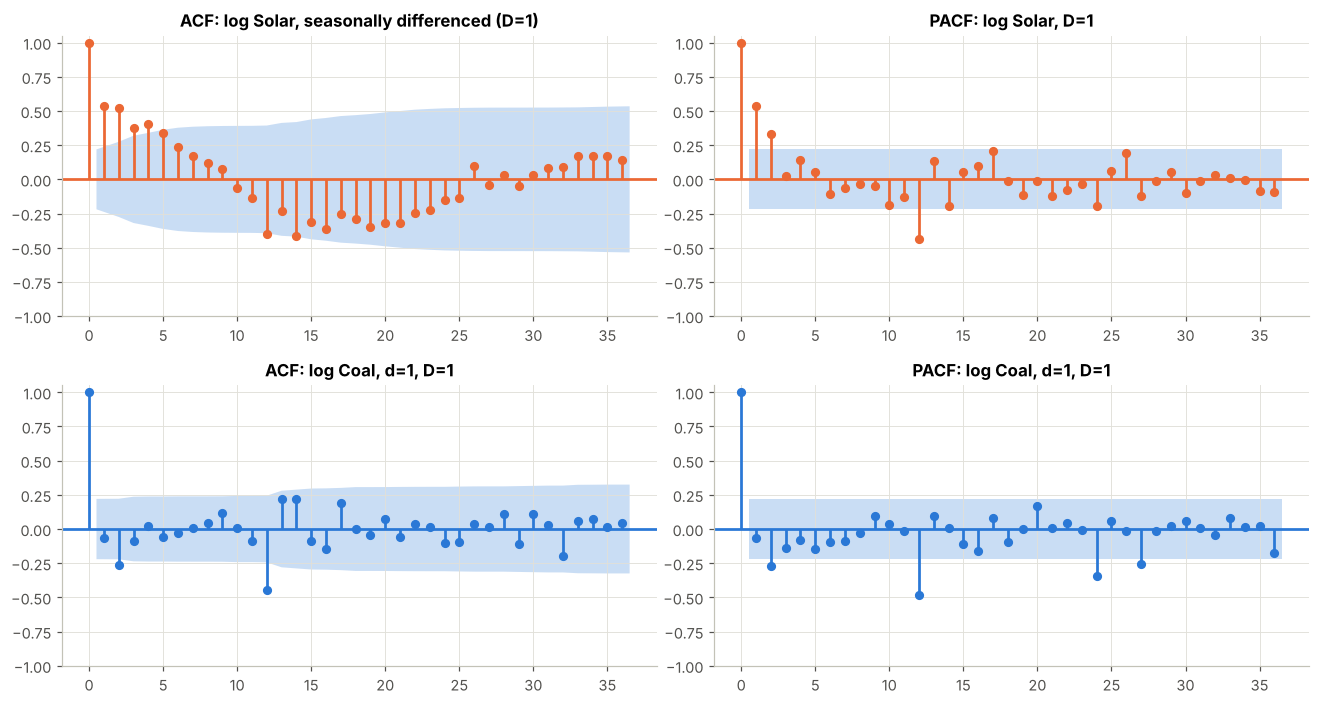

In [17]:
z_solar = np.log(y_solar).diff(12).dropna()
z_coal = np.log(y_coal).diff(12).diff().dropna()
fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
plot_acf(z_solar, lags=36, ax=ax[0, 0], title="ACF: log Solar, seasonally differenced (D=1)", color=C["solar"], vlines_kwargs={"colors": C["solar"]})
plot_pacf(z_solar, lags=36, ax=ax[0, 1], title="PACF: log Solar, D=1", method="ywm", color=C["solar"], vlines_kwargs={"colors": C["solar"]})
plot_acf(z_coal, lags=36, ax=ax[1, 0], title="ACF: log Coal, d=1, D=1", color=C["coal"], vlines_kwargs={"colors": C["coal"]})
plot_pacf(z_coal, lags=36, ax=ax[1, 1], title="PACF: log Coal, d=1, D=1", method="ywm", color=C["coal"], vlines_kwargs={"colors": C["coal"]})
for a in ax.flat: a.set_ylim(-1, 1.05)
plt.tight_layout(); plt.show()

## 9. Identifying the model
Reading the plots above (the shaded band is the 95% significance band, about ±0.22):

| Series | ACF | PACF | Suggests |
|---|---|---|---|
| log Solar (D=1) | decays gradually: about 0.54 at lag 1 and 0.52 at lag 2, fading over the next few lags; a negative spike at lag 12 (about −0.40) | significant spikes at lag 1 (about 0.54) and lag 2 (about 0.33), then cuts off; a negative spike at lag 12 (about −0.44) | **AR(2)** non-seasonal part. The lag-12 spike is the usual echo of seasonal differencing, so a seasonal MA term is worth trying |
| log Coal (d=1, D=1) | small at lag 1; negative spikes at lag 2 (about −0.26) and lag 12 (about −0.45) | negative spikes at lag 2, lag 12 (about −0.48) and lag 24 (about −0.35) | small MA/AR terms plus a **seasonal MA(1)**, e.g. the "airline" structure SARIMA(0,1,1)(0,1,1)₁₂ |

Pure AR, MA or ARMA models cannot capture a trend, and plain ARIMA cannot capture the 12-month cycle, so both series need **SARIMA**. The plots narrow the search to small orders (p, q ≤ 2, P, Q ≤ 1), seasonal terms included. The next section lets AIC/BIC choose exactly. Some candidates suggested here, such as a seasonal MA term for solar, are fitted and then discarded because their coefficient lands at the invalid boundary of −1 (the validity check in Section 10).

## 10. Identifying lags with AIC and BIC
**Stage 1:** for each differencing scheme accepted in Section 6, fit all SARIMA(p,d,q)(P,D,Q)₁₂ with p, q ∈ {0,1,2} and P, Q ∈ {0,1} (36 models per scheme) on the training data, and rank them by AIC (with BIC alongside, which penalises extra parameters more).

**Stage 2:** the AIC-best model of each scheme goes into rolling-origin cross-validation (Section 11), and the most accurate scheme wins.

For coal and total demand we include a **COVID-lockdown intervention dummy** (April-May 2020 = 1) as an exogenous regressor (SARIMAX), so that a one-off shock does not distort the estimated dynamics. It is zero in the future.

The last 12 months are held out as a test set throughout.

In [18]:
H = 12
train = {"Coal": y_coal.iloc[:-H], "Solar": y_solar.iloc[:-H], "Total": y_total.iloc[:-H]}
test = {"Coal": y_coal.iloc[-H:], "Solar": y_solar.iloc[-H:], "Total": y_total.iloc[-H:]}
exog_fn = {"Coal": T.lockdown_dummy, "Solar": None, "Total": T.lockdown_dummy}
print(f"Train: {train['Coal'].index[0]:%b %Y} - {train['Coal'].index[-1]:%b %Y} ({len(train['Coal'])} months) | "
      f"Test: {test['Coal'].index[0]:%b %Y} - {test['Coal'].index[-1]:%b %Y}")

selection = {}
for name in ["Coal", "Solar", "Total"]:
    selection[name] = T.auto_sarima(train[name], exog_fn=exog_fn[name], h=12, n_origins=6)

Train: Jan 2019 - Aug 2025 (80 months) | Test: Sep 2025 - Aug 2026


In [19]:
for name in ["Solar", "Coal"]:
    for (d, D), tbl in selection[name]["tables"].items():
        t = tbl.head(5)[["model", "AIC", "BIC", "k"]].copy()
        t["BIC rank"] = tbl["BIC"].rank().loc[t.index].astype(int)
        print(f"\n{name}: top 5 by AIC with d={d}, D={D}")
        display(t.round(2))


Solar: top 5 by AIC with d=0, D=1


,model,AIC,BIC,k,BIC rank
0,"SARIMA(2,0,0)(0,1,0)[12]",-152.71,-143.95,4,1
1,"SARIMA(2,0,1)(0,1,0)[12]",-150.71,-139.76,5,2
2,"SARIMA(1,0,1)(0,1,0)[12]",-148.30,-139.54,4,3
3,"SARIMA(1,0,2)(0,1,0)[12]",-146.72,-135.85,5,5
4,"SARIMA(2,0,2)(0,1,0)[12]",-145.35,-132.31,6,6



Coal: top 5 by AIC with d=1, D=0


,model,AIC,BIC,k,BIC rank
0,"SARIMA(0,1,1)(0,0,0)[12]",-180.15,-170.77,4,1
1,"SARIMA(1,1,0)(0,0,0)[12]",-179.76,-170.33,4,2
2,"SARIMA(2,1,0)(0,0,0)[12]",-178.07,-166.36,5,4
3,"SARIMA(0,1,0)(0,0,0)[12]",-176.39,-169.32,3,3
4,"SARIMA(0,1,2)(0,0,0)[12]",-175.72,-164.07,5,5



Coal: top 5 by AIC with d=0, D=1


,model,AIC,BIC,k,BIC rank
0,"SARIMA(1,0,0)(0,1,0)[12]",-133.11,-124.30,4,1
1,"SARIMA(0,0,1)(1,1,0)[12]",-132.65,-122.52,5,2
2,"SARIMA(0,0,2)(1,1,0)[12]",-131.69,-119.54,6,5
3,"SARIMA(2,0,2)(0,1,0)[12]",-131.46,-116.24,7,12
4,"SARIMA(1,0,2)(0,1,0)[12]",-131.08,-118.03,6,8



Coal: top 5 by AIC with d=1, D=1


,model,AIC,BIC,k,BIC rank
0,"SARIMA(1,1,1)(0,1,0)[12]",-130.37,-121.68,4,1
1,"SARIMA(0,1,2)(1,1,0)[12]",-129.07,-119.03,5,4
2,"SARIMA(2,1,1)(0,1,0)[12]",-128.44,-117.56,5,6
3,"SARIMA(0,1,2)(0,1,0)[12]",-128.14,-119.50,4,3
4,"SARIMA(0,1,1)(0,1,0)[12]",-127.39,-120.87,3,2


In [20]:
summary = pd.DataFrame([{"Series": n, "Finalist (best AIC per scheme)": m, "CV MAPE (%)": round(v, 2),
                         "Selected": "✓" if m == selection[n]["model"] else ""}
                        for n in selection for m, v in selection[n]["cv"].items()])
summary

,Series,Finalist (best AIC per scheme),CV MAPE (%),Selected
0,Coal,"SARIMA(0,1,1)(0,0,0)[12]",7.99,
1,Coal,"SARIMA(1,0,0)(0,1,0)[12]",6.76,✓
2,Coal,"SARIMA(1,1,1)(0,1,0)[12]",8.01,
3,Solar,"SARIMA(2,0,0)(0,1,0)[12]",7.65,✓
4,Total,"SARIMA(0,1,1)(0,0,0)[12]",8.02,
5,Total,"SARIMA(1,0,0)(0,1,0)[12]",3.65,✓
6,Total,"SARIMA(2,1,1)(0,1,0)[12]",4.62,


**Identified lags:** the coefficient table of the selected model shows which lags are significant.

In [21]:
def fit_selected(name, y):
    sel = selection[name]; X = exog_fn[name](y.index) if exog_fn[name] else None
    return T.fit_sarima(np.log(y), sel["order"], sel["seasonal_order"], exog=X)

fitted = {n: fit_selected(n, train[n]) for n in selection}
for n in ["Solar", "Coal"]:
    print(f"\n{n}: {selection[n]['model']}")
    tbl = pd.DataFrame({"coef": fitted[n].params, "std err": fitted[n].bse, "p-value": fitted[n].pvalues})
    display(tbl.round(4))


Solar: SARIMA(2,0,0)(0,1,0)[12]


,coef,std err,p-value
intercept,0.065,0.025,0.011
ar.L1,0.285,0.142,0.044
ar.L2,0.436,0.107,0.000
sigma2,0.005,0.001,0.000



Coal: SARIMA(1,0,0)(0,1,0)[12]


,coef,std err,p-value
intercept,0.024,0.013,0.06
lockdown,-0.191,0.035,0.00
ar.L1,0.503,0.101,0.00
sigma2,0.007,0.001,0.00


## 11. Model evaluation
### 11.1 Hold-out test (last 12 months)
The selected SARIMA is compared with two benchmarks: **Seasonal naive** (repeat last year) and **Holt-Winters** (damped additive trend and additive seasonality on logs). All errors are in TWh, on the original scale.

In [22]:
def forecast_all(name, tr, h):
    sel = selection[name]
    return {
        "Seasonal naive": T.seasonal_naive(tr, h),
        "Holt-Winters": np.exp(T.holt_winters(np.log(tr), h)),
        "SARIMA": T.sarima_forecaster(sel["order"], sel["seasonal_order"], exog_fn[name])(tr, h),
    }

holdout, preds = [], {}
for name in ["Coal", "Solar", "Total"]:
    preds[name] = forecast_all(name, train[name], H)
    for m, p in preds[name].items():
        holdout.append({"Series": name, "Model": m, **T.metrics(test[name], p)})
holdout = pd.DataFrame(holdout).set_index(["Series", "Model"]).round(2)
holdout

RMSE    MAE  MAPE (%)
Series Model                                 
Coal   Seasonal naive   9.07   7.35      6.62
       Holt-Winters     6.06   4.99      4.47
       SARIMA           8.75   7.24      6.74
Solar  Seasonal naive   5.99   5.83     27.26
       Holt-Winters     2.34   2.13      9.86
       SARIMA           2.02   1.71      7.96
Total  Seasonal naive  12.52  10.84      6.34
       Holt-Winters     8.38   6.93      4.05
       SARIMA           7.99   6.43      3.92

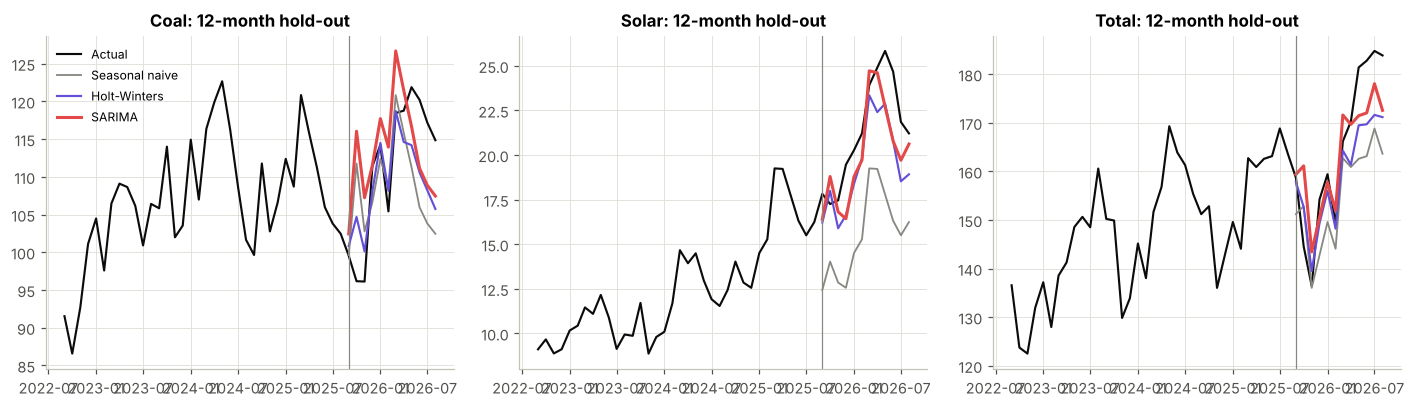

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
styles = {"Seasonal naive": dict(color=C["muted"], lw=1.2), "Holt-Winters": dict(color="#6250d6", lw=1.4), "SARIMA": dict(color="#e34948", lw=2)}
for a, name in zip(ax, ["Coal", "Solar", "Total"]):
    y = {"Coal": y_coal, "Solar": y_solar, "Total": y_total}[name]
    a.plot(y.iloc[-48:], color=C["ink"], lw=1.4, label="Actual")
    for m, p in preds[name].items(): a.plot(p, label=m, **styles[m])
    a.axvline(test[name].index[0], color=C["muted"], lw=0.8); a.set_title(f"{name}: 12-month hold-out")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 11.2 Rolling-origin cross-validation
A single 12-month hold-out is one draw of luck. We refit every model at 12 forecast origins (expanding window) and average the error at each horizon from 1 to 12 months ahead.

In [24]:
cv_all = []
for name in ["Coal", "Solar", "Total"]:
    sel, y = selection[name], {"Coal": y_coal, "Solar": y_solar, "Total": y_total}[name]
    f = {"Seasonal naive": lambda tr, h: T.seasonal_naive(tr, h),
         "Holt-Winters": lambda tr, h: np.exp(T.holt_winters(np.log(tr), h)),
         "SARIMA": T.sarima_forecaster(sel["order"], sel["seasonal_order"], exog_fn[name])}
    cv_all.append(T.rolling_origin_cv(y, f, h=12, n_origins=12).assign(Series=name))
cv_all = pd.concat(cv_all)
cv_table = cv_all.pivot_table(index="Series", columns="model", values="ape", aggfunc="mean").round(2)
print("Mean absolute percentage error over 12 origins x 12 horizons (%)")
cv_table

Mean absolute percentage error over 12 origins x 12 horizons (%)


model,Holt-Winters,SARIMA,Seasonal naive
Series,,,
Coal,5.05,8.18,5.22
Solar,8.54,7.32,25.80
Total,2.79,3.51,4.60


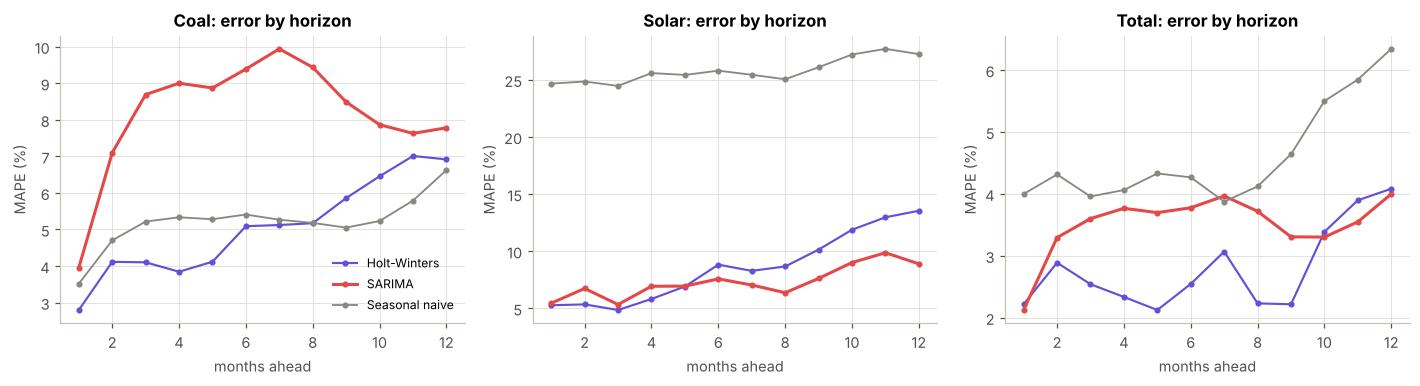

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for a, name in zip(ax, ["Coal", "Solar", "Total"]):
    t = cv_all[cv_all.Series == name].groupby(["model", "horizon"]).ape.mean().unstack(0)
    for m in t: a.plot(t.index, t[m], marker="o", ms=3, label=m, **styles[m])
    a.set_title(f"{name}: error by horizon"); a.set_xlabel("months ahead"); a.set_ylabel("MAPE (%)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Reading the results.** No single model wins everywhere, and the cross-validation shows where each one is strong:
- **Solar:** SARIMA is the most accurate model. Solar's large and growing seasonal cycle is exactly the structure a seasonal ARIMA on logs captures, and the seasonal-naive baseline is far behind because it ignores growth.
- **Coal and total demand:** damped Holt-Winters is more accurate. India's coal generation *fell* 3.3% in 2025, its first fall outside the COVID year: total generation grew only about 2.5% while solar alone added about 53 TWh. Coal then rebounded in 2026. A SARIMA with drift keeps projecting the pre-2025 growth, while a damped trend adapts to the break faster.

SARIMA is still kept as the main model, because the later sections need its prediction intervals and its ability to simulate future paths. The lesson for deployment is that the best point forecaster can differ by series, which is why the app shows both models side by side.

### 11.3 Residual diagnostics (SARIMA, fitted on the training data)

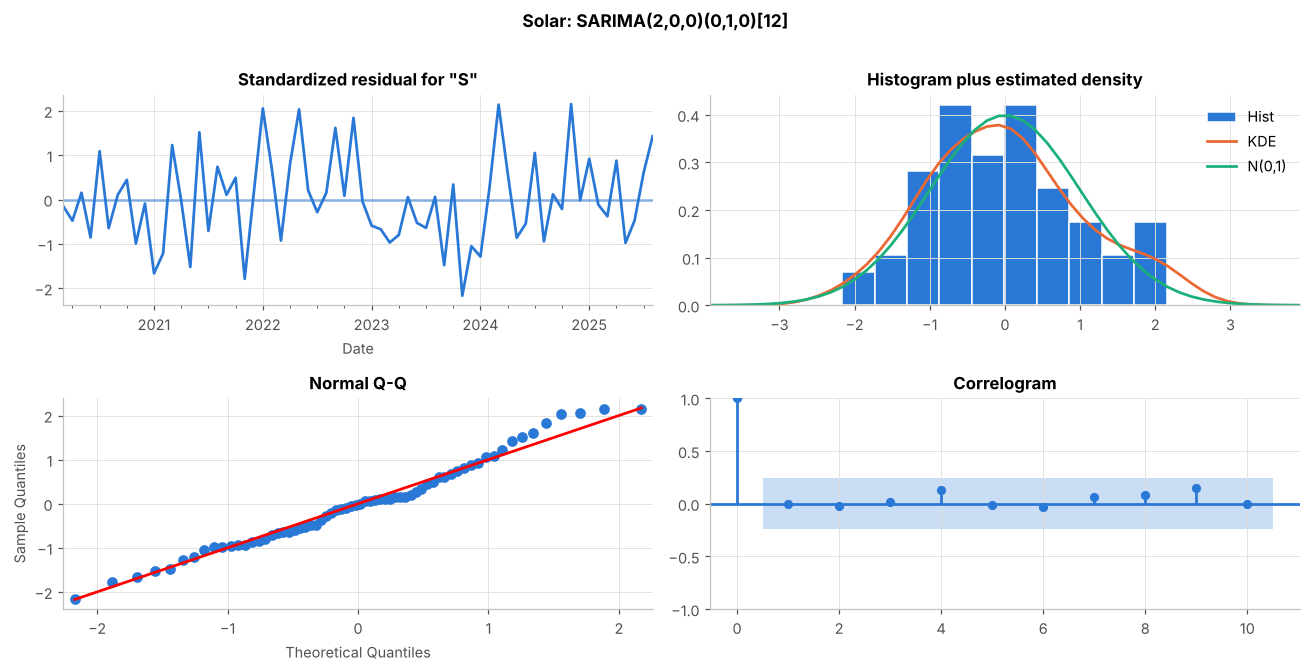

Solar Ljung-Box p-values: {6: 0.977, 12: 0.082} (p > 0.05 means no leftover autocorrelation)


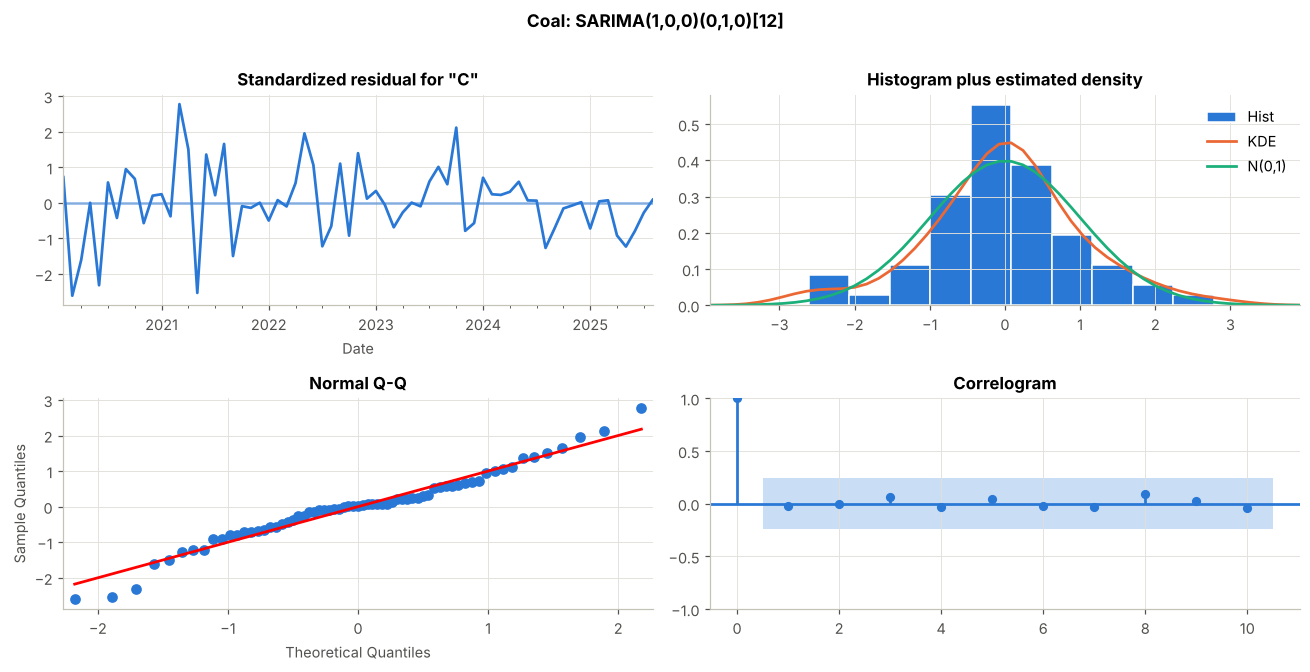

Coal Ljung-Box p-values: {6: 0.997, 12: 0.124} (p > 0.05 means no leftover autocorrelation)


In [26]:
for n in ["Solar", "Coal"]:
    fig = fitted[n].plot_diagnostics(figsize=(12, 6)); fig.suptitle(f"{n}: {selection[n]['model']}", y=1.01, fontweight="bold")
    plt.tight_layout(); plt.show()
    burn = sum(selection[n]["seasonal_order"][1:2]) * 12 + selection[n]["order"][1] + 1
    lb = acorr_ljungbox(fitted[n].resid.iloc[burn:], lags=[6, 12], return_df=True)
    print(n, "Ljung-Box p-values:", lb["lb_pvalue"].round(3).to_dict(), "(p > 0.05 means no leftover autocorrelation)")

## 12. 24-month forecasts
The selected models are refitted on all data and projected 24 months ahead with 80% and 95% prediction intervals.

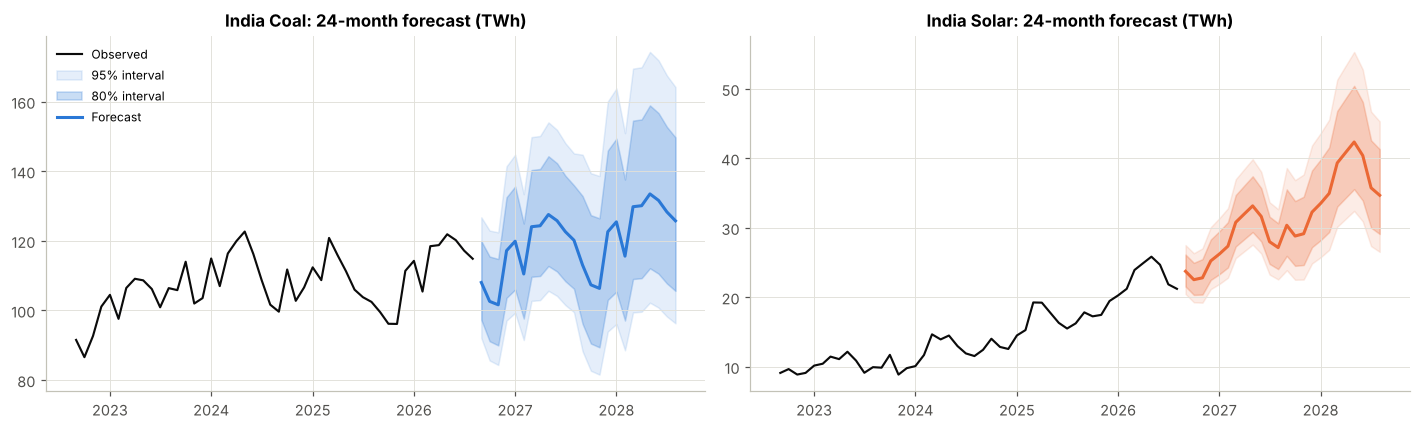

Coal                  Solar            
         forecast   lo80   hi80 forecast  lo80  hi80
Sep 2026    108.0   97.3  119.9     23.7  21.6  26.1
Dec 2026    117.2  103.6  132.5     25.2  22.5  28.3
Mar 2027    124.1  109.7  140.3     30.8  27.3  34.7
Jun 2027    125.8  111.2  142.3     31.6  28.0  35.7
Sep 2027    113.0   96.2  132.9     30.4  26.0  35.5
Dec 2027    122.6  103.0  145.9     32.2  27.2  38.2
Mar 2028    129.8  109.0  154.5     39.3  33.0  46.8
Jun 2028    131.6  110.6  156.7     40.4  33.9  48.1

In [27]:
fc24 = {}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (name, y) in zip(ax, [("Coal", y_coal), ("Solar", y_solar)]):
    res = fit_selected(name, y)
    k = res.model.k_exog
    f = res.get_forecast(24, exog=np.zeros((24, k)) if k else None)
    mid, ci80, ci95 = np.exp(f.predicted_mean), np.exp(f.conf_int(alpha=0.2)), np.exp(f.conf_int(alpha=0.05))
    col = C[name.lower()]
    a.plot(y.iloc[-48:], color=C["ink"], lw=1.4, label="Observed")
    a.fill_between(ci95.index, ci95.iloc[:, 0], ci95.iloc[:, 1], color=col, alpha=0.12, label="95% interval")
    a.fill_between(ci80.index, ci80.iloc[:, 0], ci80.iloc[:, 1], color=col, alpha=0.25, label="80% interval")
    a.plot(mid, color=col, lw=2, label="Forecast"); a.set_title(f"India {name}: 24-month forecast (TWh)")
    fc24[name] = pd.DataFrame({"forecast": mid, "lo80": ci80.iloc[:, 0], "hi80": ci80.iloc[:, 1]})
ax[0].legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()
both = pd.concat(fc24, axis=1).round(1); both.index = both.index.strftime("%b %Y")
both.iloc[::3]

## 13. Extension A: when will solar overtake coal?
### 13.1 Why model the log-ratio?
Forecasting solar and coal separately and seeing where the lines cross ignores that the two series are linked: when solar grows, it displaces coal. We model their ratio directly:

$$r_t = \log\left(\frac{\text{Solar}_t}{\text{Coal}_t}\right), \qquad \text{solar beats coal in month } t \iff r_t > 0.$$

The crossover is then a **first-passage time**: the first time a stochastic process crosses zero. A SARIMA forecast gives an expected path. To get the *distribution* of the crossing date we **simulate 2,000 future paths** from the fitted model (each path draws new random shocks every month) and record when each path first crosses zero.

**Parameter uncertainty.** A standard simulation treats the estimated coefficients as exact. Over a 10-25 year horizon the biggest unknown is the trend itself, so whenever the selected model has a drift term we draw the drift from its sampling distribution N(ĉ, se²) 100 times, re-run the Kalman filter with each draw, and simulate 20 paths per draw. Without this step the crossover ranges come out far too narrow; Section 15.1 checks the calibration.

All models are fitted with stationarity and invertibility enforced, so a simulation can never explode from a coefficient sitting outside the valid region.

Two definitions are reported:
- **First month:** the first month in which solar out-generates coal (likely in a sunny spring month).
- **First year (the headline):** the first calendar year in which solar beats coal *on average* (mean of r_t over the year > 0).

In [28]:
r_sel = T.auto_sarima(ratio, exog_fn=T.lockdown_dummy, transform=T.identity, back=T.identity, score="ae", n_origins=6)
print("Selected log-ratio model:", r_sel["model"], "| CV MAE by finalist:", {k: round(v, 3) for k, v in r_sel["cv"].items()})
r_res = T.fit_sarima(ratio, r_sel["order"], r_sel["seasonal_order"], exog=T.lockdown_dummy(ratio.index))
cx = T.crossover_distribution(ratio, r_res, end_year=2050, n_paths=2000, seed=0)
cross = pd.DataFrame({k: T.summarise_crossover(cx[k]) for k in ["month", "year"]}).T
cross.index = ["First month solar > coal", "First year solar > coal"]
cross.round(3).replace(np.inf, "after 2050")

Selected log-ratio model: SARIMA(2,1,0)(0,1,0)[12] | CV MAE by finalist: {'SARIMA(2,1,0)(0,1,0)[12]': 0.07}


,P(before 2050),P(by 2030),P(by 2035),P(by 2040),median,p10,p90
First month solar > coal,0.714,0.150,0.553,0.648,2033.5,2029.667,after 2050
First year solar > coal,0.688,0.194,0.526,0.622,2035.0,2030.000,after 2050


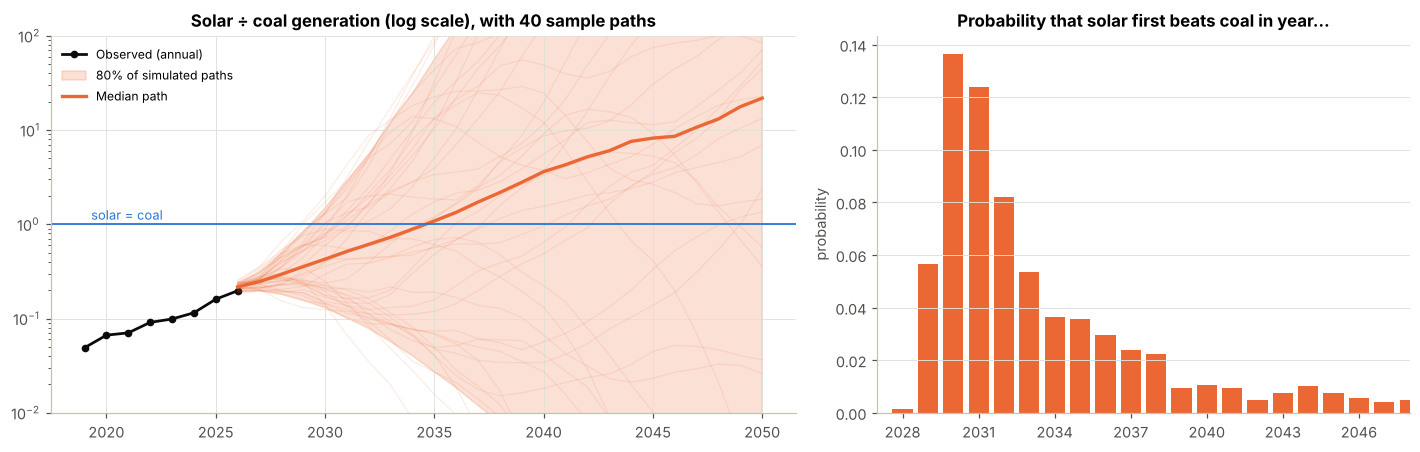

In [29]:
paths = cx["paths"]; ann = paths.groupby(paths.index.year).mean()
hist_ann = ratio.groupby(ratio.index.year).mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax[0].plot(hist_ann.index, np.exp(hist_ann), color=C["ink"], marker="o", ms=4, label="Observed (annual)")
for i in range(40): ax[0].plot(ann.index, np.exp(ann.iloc[:, i]), color=C["solar"], alpha=0.12, lw=0.8)
ax[0].fill_between(ann.index, np.exp(ann.quantile(0.1, axis=1)), np.exp(ann.quantile(0.9, axis=1)), color=C["solar"], alpha=0.2, label="80% of simulated paths")
ax[0].plot(ann.index, np.exp(ann.median(axis=1)), color=C["solar"], lw=2.2, label="Median path")
ax[0].axhline(1, color=C["coal"], lw=1.2); ax[0].text(2019.3, 1.12, "solar = coal", color=C["coal"], fontsize=8.5)
ax[0].set_yscale("log"); ax[0].set_ylim(1e-2, 1e2)   # a few double-differenced paths run far outside this range
ax[0].set_title("Solar ÷ coal generation (log scale), with 40 sample paths"); ax[0].legend(loc="upper left", fontsize=8)
yrs = cx["year"]; bins = np.arange(int(np.nanmin(yrs)), 2051)
p = [np.mean(yrs == b) for b in bins]
ax[1].bar(bins, p, color=C["solar"], width=0.8); ax[1].set_title("Probability that solar first beats coal in year…")
ax[1].set_xlim(bins[0] - 1, min(2050, bins[0] + 20)); ax[1].set_ylabel("probability")
ax[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 13.2 Is the method trustworthy? Backtest and sensitivity

In [30]:
# (1) Backtest: fit the same model on data up to Aug 2023 only, forecast the next 36 months, compare with reality
cut = ratio.index[-37]
r_old = T.fit_sarima(ratio[:cut], r_sel["order"], r_sel["seasonal_order"], exog=T.lockdown_dummy(ratio[:cut].index))
f_old = r_old.get_forecast(36, exog=np.zeros((36, 1)))
lo, hi = f_old.conf_int(alpha=0.2).values.T
act = ratio[cut:].iloc[1:37]
print(f"Fitted to {cut:%b %Y}, forecasting {act.index[0]:%b %Y}-{act.index[-1]:%b %Y}: "
      f"{np.mean((act.values >= lo) & (act.values <= hi)) * 100:.0f}% of actual months inside the 80% interval, "
      f"MAE = {np.mean(np.abs(act.values - f_old.predicted_mean.values)):.3f} log points")

# (2) Sensitivity: how much does the answer depend on which SARIMA we pick?
specs = {r_sel["model"]: (r_sel["order"], r_sel["seasonal_order"]),
         "SARIMA(0,1,1)(1,0,1)[12] + drift": ((0, 1, 1), (1, 0, 1, 12)),
         "SARIMA(1,1,0)(1,0,0)[12] + drift": ((1, 1, 0), (1, 0, 0, 12))}
sens = {}
for lbl, (o, so) in specs.items():
    rr = T.fit_sarima(ratio, o, so, exog=T.lockdown_dummy(ratio.index))
    sens[lbl] = T.summarise_crossover(T.crossover_distribution(ratio, rr, n_paths=2000)["year"])
pd.DataFrame(sens).T[["median", "p10", "p90", "P(by 2030)", "P(by 2035)", "P(by 2040)"]].round(2).replace(np.inf, "after 2050")

Fitted to Aug 2023, forecasting Sep 2023-Aug 2026: 89% of actual months inside the 80% interval, MAE = 0.252 log points


,median,p10,p90,P(by 2030),P(by 2035),P(by 2040)
"SARIMA(2,1,0)(0,1,0)[12]",2035.0,2030.0,after 2050,0.19,0.53,0.62
"SARIMA(0,1,1)(1,0,1)[12] + drift",2035.0,2031.0,after 2050,0.06,0.52,0.64
"SARIMA(1,1,0)(1,0,0)[12] + drift",2037.0,2030.0,after 2050,0.11,0.45,0.59


The three reasonable model structures give similar median crossover years. They differ mainly in how *wide* the uncertainty is, which is exactly what the probabilistic framing exposes. The selected model differences twice (d = 1 and D = 1), which lets the *growth rate* of the ratio wander, so its uncertainty grows quickly with the horizon and a few simulated paths run far off the chart above. The two drift models assume a steady average growth rate and spread more slowly, yet give nearly the same median. The backtest's 89% coverage of an 80% interval says the selected model is, if anything, cautious. The simulation assumes that the recent trend in the solar-to-coal ratio continues. Policy changes, storage costs or a coal-plant pipeline could bend it, and Section 17 discusses this.

## 14. Extension B: will India reach 500 GW of non-fossil capacity by 2030?
India's stated target (COP26, 2021) is **500 GW of non-fossil installed capacity by 2030**. Ember's yearly file gives "Clean" capacity (renewables + nuclear, the same definition) from 2000. This is an **annual** series (26 points), so we use non-seasonal ARIMA on log capacity.

In [31]:
cap = yearly[yearly["Area"] == "India"].pivot_table(index="Year", columns="Electricity source", values="Capacity (GW)")["Clean"]
zc = np.log(cap); zc.index = pd.period_range(str(cap.index[0]), periods=len(cap), freq="Y")
display(pd.DataFrame([T.stationarity_report(zc, "log capacity"), T.stationarity_report(zc.diff(), "growth rate (d=1)"),
                      T.stationarity_report(zc.diff().diff(), "change in growth rate (d=2)")]))
last = int(cap.index[-1])
need = ((500 / cap.iloc[-1]) ** (1 / (2030 - last)) - 1) * 100
print(f"Capacity {last}: {cap.iloc[-1]:.0f} GW | required growth to 2030: {need:.1f}%/yr | achieved: "
      + ", ".join(f"{a}-{last}: {((cap.iloc[-1] / cap[a]) ** (1 / (last - a)) - 1) * 100:.1f}%/yr" for a in (2000, 2015, 2020)))

,Series,ADF stat,ADF p-value,KPSS p-value,Verdict
0,log capacity,2.734,0.999,0.010,non-stationary
1,growth rate (d=1),0.651,0.989,0.074,non-stationary
2,change in growth rate (d=2),-3.476,0.009,0.100,stationary


Capacity 2025: 259 GW | required growth to 2030: 14.1%/yr | achieved: 2000-2025: 9.3%/yr, 2015-2025: 11.9%/yr, 2020-2025: 12.9%/yr


The growth rate itself is not stationary (ADF cannot reject a unit root at d = 1): India's clean-capacity growth has been **accelerating**. That gives two defensible models, which encode two different beliefs about the future:
- **Long-run trend (d = 1, with drift):** growth fluctuates around its 25-year average.
- **Accelerating growth (d = 2):** the growth rate is itself a random walk, so the recent surge carries forward.

AIC cannot arbitrate between different d. We therefore report both, and backtest each one: refit at every origin from 2015 to 2020 and forecast 5 years ahead.

In [32]:
scen = {}
for label, d in [("Long-run trend", 1), ("Accelerating growth", 2)]:
    t = T.target_analysis(cap, 500, 2030, d); scen[label] = t
    errs = []
    for end in range(2015, 2021):
        r_bt = T.annual_arima(zc[:str(end)], d)
        f_bt = np.exp(r_bt.forecast(5)); a_bt = cap.loc[end + 1:end + 5]
        errs.append(np.mean(np.abs(f_bt.values - a_bt.values) / a_bt.values) * 100)
    t["backtest_mape"] = np.mean(errs)
pd.DataFrame({k: {"model": v["model"], "median 2030 (GW)": round(v["fan"]["median"].iloc[-1]),
                  "80% interval (GW)": f"{v['fan']['p10'].iloc[-1]:.0f} - {v['fan']['p90'].iloc[-1]:.0f}",
                  "P(≥ 500 GW by 2030)": f"{v['p_hit']:.0%}", "5-yr backtest MAPE": f"{v['backtest_mape']:.1f}%"}
              for k, v in scen.items()}).T

,model,median 2030 (GW),80% interval (GW),P(≥ 500 GW by 2030),5-yr backtest MAPE
Long-run trend,"ARIMA(0, 1, 1) on log capacity + drift",423,358 - 502,11%,6.1%
Accelerating growth,"ARIMA(0, 2, 1) on log capacity",576,439 - 759,75%,9.9%


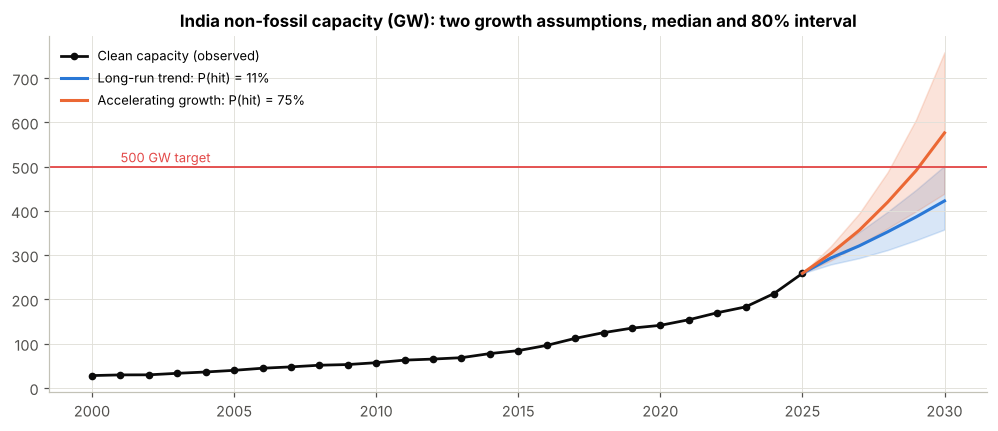

In [33]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(cap.index, cap.values, color=C["ink"], marker="o", ms=4, label="Clean capacity (observed)")
for (label, t), c in zip(scen.items(), [C["coal"], C["solar"]]):
    f = t["fan"]; xs = [last] + list(f.index)
    ax.fill_between(xs, [cap.iloc[-1]] + list(f["p10"]), [cap.iloc[-1]] + list(f["p90"]), color=c, alpha=0.18)
    ax.plot(xs, [cap.iloc[-1]] + list(f["median"]), color=c, lw=2, label=f"{label}: P(hit) = {t['p_hit']:.0%}")
ax.axhline(500, color="#e34948", lw=1.2); ax.text(2001, 510, "500 GW target", color="#e34948", fontsize=8.5)
ax.set_title("India non-fossil capacity (GW): two growth assumptions, median and 80% interval"); ax.legend(loc="upper left", fontsize=8.5)
plt.show()

The answer depends on whether the 2024-25 surge is the new normal. If growth reverts to its long-run pace, the target is very unlikely. If the acceleration persists, reaching it is more likely than not. The long-run model has the lower backtest error, but both models under-predicted the 2024-25 jump. That should count as a warning against confidently writing the target off. This is a policy-relevant answer that a single forecast line would hide.

## 15. Extension C: the same pipeline on 80+ countries
`build_results.py` runs the full procedure (missing-value rule → log transform → differencing tests → AIC per scheme → cross-validation across schemes → simulation) for every country with at least 5 years of monthly data, using a reduced lag grid for speed. Its output feeds the web app and dashboard.

In [34]:
if not os.path.exists("results/results.json"):
    !python build_results.py
res_all = json.load(open("results/results.json"))
rows = []
for c in res_all["countries"]:
    if c["status"] not in ("forecast", "crossed"): continue
    y = c["crossover"]["year"]
    rows.append({"Country": c["country"], "Coal share %": c["share12"].get("Coal"), "Solar share %": c["share12"].get("Solar"),
                 "Solar ÷ coal (last 12m)": c["last12_ratio"], "Status": c["status"],
                 "Median crossover year": None if c["status"] == "crossed" else y["median"],
                 "P(by 2030)": y["P(by 2030)"], "P(by 2035)": y["P(by 2035)"]})
league = pd.DataFrame(rows).sort_values("Solar ÷ coal (last 12m)", ascending=False).reset_index(drop=True)
print(f"{len(league)} countries with meaningful coal generation | already crossed: {(league.Status == 'crossed').sum()}")
league.head(25)

37 countries with meaningful coal generation | already crossed: 11


,Country,Coal share %,Solar share %,Solar ÷ coal (last 12m),Status,Median crossover year,P(by 2030),P(by 2035)
0,Italy,1.02,19.65,17.726,crossed,NaN,1.000,1.000
1,Brazil,1.48,13.80,9.805,crossed,NaN,1.000,1.000
2,Hungary,3.67,30.71,6.864,crossed,NaN,1.000,1.000
3,Argentina,1.80,4.18,4.436,crossed,NaN,1.000,1.000
4,Greece,5.24,23.14,4.242,crossed,NaN,1.000,1.000
5,Netherlands,8.22,20.53,2.155,crossed,NaN,1.000,1.000
6,Slovenia,12.03,13.13,1.948,crossed,NaN,0.896,0.911
7,Colombia,4.18,5.29,1.538,crossed,NaN,0.978,0.989
8,Pakistan,16.65,24.09,1.470,crossed,NaN,0.947,0.959
9,Chile,17.85,25.55,1.415,crossed,NaN,1.000,1.000


### 15.1 Are the probabilistic forecasts honest? (calibration)
For every country, each model was refitted with its last 12 months removed. We then checked how often the true values fell inside the 80% prediction interval. A well-calibrated forecaster scores about 80%. Calibration is rarely checked in student projects, yet it is what makes probability statements such as "60% by 2035" meaningful.

,countries,mean_coverage,median_mape
series,,,
Coal,42,0.772,16.723
LogRatio,37,0.809,NaN
Solar,62,0.852,14.310


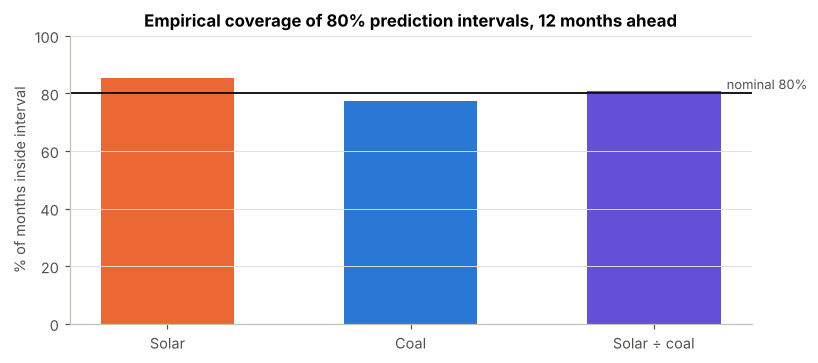

In [35]:
cal = []
for c in res_all["countries"]:
    for k, v in c.get("calibration", {}).items():
        cal.append({"country": c["country"], "series": k, "cover80": v["cover80"], "mape": v.get("mape")})
cal = pd.DataFrame(cal)
summary_cal = cal.groupby("series").agg(countries=("country", "count"), mean_coverage=("cover80", "mean"),
                                        median_mape=("mape", "median")).round(3)
display(summary_cal)
fig, ax = plt.subplots(figsize=(8, 3.4))
order = ["Solar", "Coal", "LogRatio"]
ax.bar(["Solar", "Coal", "Solar ÷ coal"], [summary_cal.loc[s, "mean_coverage"] * 100 for s in order], color=[C["solar"], C["coal"], C["hydro"]], width=0.55)
ax.grid(axis="x", visible=False)
ax.axhline(80, color=C["ink"], lw=1.2); ax.text(2.3, 81.5, "nominal 80%", fontsize=8.5, color=C["ink2"])
ax.set_ylim(0, 100); ax.set_ylabel("% of months inside interval"); ax.set_title("Empirical coverage of 80% prediction intervals, 12 months ahead")
plt.show()

## 16. Deployment
The model is deployed in two complementary ways, both on free hosting:

| Component | What it does | Where |
|---|---|---|
| `transition.py` | Shared library: tests, model selection, simulation, target analysis | used by everything below |
| `build_results.py` | Batch run for all countries → `results/results.json` | run locally (≈ 20 min) or on a schedule |
| `app.py` (Streamlit) | **Live model fitting**: pick any country and source, choose automatic or manual SARIMA orders, see the AIC/BIC table, diagnostics, forecast and crossover probability, recomputed on the spot | Streamlit Community Cloud (free) |
| Web dashboard | Static, instant-loading explorer of the precomputed results for every country, with the India 2030 tracker | published link (free) |

Run the app locally:
```
pip install -r requirements.txt
streamlit run app.py
```

## 17. Conclusion

In [36]:
s_cv, c_cv = cv_table.loc["Solar"], cv_table.loc["Coal"]
yr = cross.loc["First year solar > coal"]
print("=== KEY RESULTS ===")
print(f"Data                    : Ember, India {india.index[0]:%b %Y}-{india.index[-1]:%b %Y} ({len(india)} months), {res_all['countries'].__len__()} countries in total")
print(f"Selected models         : Solar {selection['Solar']['model']} | Coal {selection['Coal']['model']} (+ lockdown dummy)")
print(f"Solar forecast error    : SARIMA {s_cv['SARIMA']:.1f}% vs Holt-Winters {s_cv['Holt-Winters']:.1f}% vs seasonal naive {s_cv['Seasonal naive']:.1f}% (CV MAPE)")
print(f"Coal forecast error     : SARIMA {c_cv['SARIMA']:.1f}% vs Holt-Winters {c_cv['Holt-Winters']:.1f}% vs seasonal naive {c_cv['Seasonal naive']:.1f}% (CV MAPE)")
yfmt = lambda v: "after 2050" if not np.isfinite(v) else f"{v:.0f}"
print(f"Solar > coal (annual)   : median {yfmt(yr['median'])}, 80% interval {yfmt(yr['p10'])} to {yfmt(yr['p90'])}, "
      f"P(by 2035) = {yr['P(by 2035)']:.0%}, P(before 2051) = {yr['P(before 2050)']:.0%}")
ind = next(c for c in res_all["countries"] if c["country"] == "India")["crossover"]["year"]
print(f"  same question, automated pipeline (small grid, no lockdown dummy): median {ind['median']:.0f}, P(by 2035) = {ind['P(by 2035)']:.0%}")
for k, v in scen.items():
    print(f"500 GW by 2030 ({k:19s}): P = {v['p_hit']:.0%}, median {v['fan']['median'].iloc[-1]:.0f} GW")
print(f"Interval calibration    : " + ", ".join(f"{s} {summary_cal.loc[s, 'mean_coverage']:.0%}" for s in order) + " coverage of nominal 80%")

=== KEY RESULTS ===
Data                    : Ember, India Jan 2019-Aug 2026 (92 months), 82 countries in total
Selected models         : Solar SARIMA(2,0,0)(0,1,0)[12] | Coal SARIMA(1,0,0)(0,1,0)[12] (+ lockdown dummy)
Solar forecast error    : SARIMA 7.3% vs Holt-Winters 8.5% vs seasonal naive 25.8% (CV MAPE)
Coal forecast error     : SARIMA 8.2% vs Holt-Winters 5.0% vs seasonal naive 5.2% (CV MAPE)
Solar > coal (annual)   : median 2035, 80% interval 2030 to after 2050, P(by 2035) = 53%, P(before 2051) = 69%
  same question, automated pipeline (small grid, no lockdown dummy): median 2034, P(by 2035) = 59%
500 GW by 2030 (Long-run trend     ): P = 11%, median 423 GW
500 GW by 2030 (Accelerating growth): P = 75%, median 576 GW
Interval calibration    : Solar 85%, Coal 77%, LogRatio 81% coverage of nominal 80%


### Summary of findings
1. **Forecast accuracy (RQ1).** One to twelve months ahead, India's solar generation can be forecast to about 7% (MAPE), and SARIMA beats both benchmarks. Total demand is forecastable to about 3-4%. Coal is harder (5-8%) because of the 2025 break, and damped Holt-Winters handles it best.
2. **Solar vs coal (RQ2).** India's solar output has grown from about 5% to about 19% of coal's output since 2019. If the trend in that ratio continues, the most likely first full year of solar out-generating coal is the mid-2030s, with roughly even odds by 2035. The interval is wide: about three in ten simulated futures do not cross before 2051. Different reasonable SARIMA structures, and the simpler automated pipeline, agree on the median within about two years.
3. **The 500 GW target (RQ3).** The target needs 14% annual growth, more than India has ever sustained over five years. If growth reverts to its long-run trend, the chance is about 1 in 10. If the 2024-25 acceleration continues, it is about 3 in 4. The policy question is therefore whether the recent surge in additions persists.
4. **Generalisation and honesty (RQ4).** Across 37 countries with meaningful coal generation, 11 already generate more from solar than from coal. When the last year was held out, the 80% intervals contained 77-85% of actual months, so the probability statements are reasonably calibrated.

### Limitations and future work
- The models extrapolate statistical trends. Prices, storage, policy and new coal plants are not modelled; a structural model with exogenous drivers (installed capacity, demand, weather) is the natural next step.
- Monthly data for India starts in 2019 (92 months), which makes decade-ahead intervals wide. That is intended: it is what the data can support.
- The crossover simulation includes uncertainty in the drift but not in the other coefficients or in the choice of model, so true uncertainty is somewhat larger than shown.
- Ember data are compiled from national sources and revised; reruns can shift results slightly.

### References
- Ember (2026). *Monthly and yearly electricity data*, CC-BY-4.0. https://ember-energy.org
- Hyndman, R.J. & Athanasopoulos, G. *Forecasting: Principles and Practice*, 3rd ed. OTexts (seasonal strength, time-series cross-validation, auto-ARIMA).
- Box, G.E.P., Jenkins, G.M., Reinsel, G.C. & Ljung, G.M. *Time Series Analysis: Forecasting and Control*. Wiley.
- Seabold, S. & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python.
- Government of India, Ministry of New and Renewable Energy: 500 GW non-fossil capacity target for 2030 (COP26 announcement, 2021).